# Eksploracja danych — brakujące wartości

**Cel zajęć:** nauczyć się *znajdować* braki (także te ukryte), *diagnozować*, czy są przypadkowe, i *świadomie wybierać*, czy je usunąć, czy uzupełnić.

**Plan:**
1. Rozgrzewka na zbiorze **Titanic** — te same kroki co na wykładzie.
2. Zadanie główne: **oferty mieszkań** (`nieruchomosci.csv`) — prawdziwy bałagan.

**Zadania:** 🟢 podstawowe (obowiązkowe), 🔵 dla ambitnych.

**Jak pracować:** w Colabie wybierz *Plik → Zapisz kopię na Dysku*, wgraj plik `nieruchomosci.csv` (ikona folderu po lewej → *Prześlij*), rozwiąż zadania w miejscach `# TODO`, a gotowy notatnik umieść w swoim repozytorium na GitHubie.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 11})

URL_TITANIC = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
titanic = pd.read_csv("titanic.csv") if Path("titanic.csv").exists() else pd.read_csv(URL_TITANIC)

if not Path("nieruchomosci.csv").exists():
    print("⚠️ Wgraj plik nieruchomosci.csv do bieżącego katalogu (w Colabie: ikona folderu → Prześlij).")

print(titanic.shape)
titanic.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


---
# Część 1. Rozgrzewka: Titanic

| kolumna | znaczenie |
|---|---|
| `Survived` | czy pasażer przeżył (1 = tak) |
| `Pclass` | klasa biletu (1, 2, 3) |
| `Sex`, `Age` | płeć, wiek |
| `SibSp`, `Parch` | liczba rodzeństwa/małżonków oraz rodziców/dzieci na pokładzie |
| `Fare` | cena biletu (£) |
| `Cabin` | numer kabiny |
| `Embarked` | port zaokrętowania: C — Cherbourg, Q — Queenstown, S — Southampton |

### 🟢 Zadanie 1: ile jest braków?

1. Policz liczbę i odsetek braków w każdej kolumnie. Pokaż tylko kolumny, w których braki występują, posortowane malejąco.
2. Narysuj poziomy wykres słupkowy odsetka braków (`.plot.barh()`), z opisem osi.

,Liczba braków,Odsetek braków (%)
Cabin,687,77.104377
Age,177,19.865320
Embarked,2,0.224467


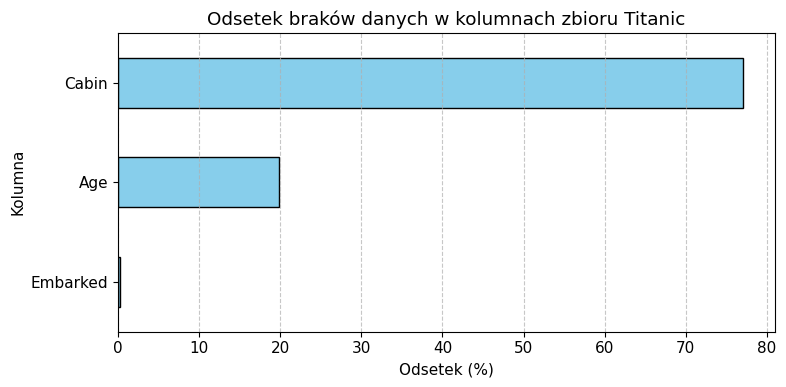

In [3]:
null_counts = titanic.isna().sum()
null_percentages = (titanic.isna().mean() * 100)


missing_data = pd.DataFrame({
    'Liczba braków': null_counts,
    'Odsetek braków (%)': null_percentages
})

missing_data = missing_data[missing_data['Liczba braków'] > 0].sort_values(by='Liczba braków', ascending=False)
display(missing_data)

plt.figure(figsize=(8, 4))
missing_data['Odsetek braków (%)'].sort_values().plot.barh(color='skyblue', edgecolor='black')
plt.title('Odsetek braków danych w kolumnach zbioru Titanic')
plt.xlabel('Odsetek (%)')
plt.ylabel('Kolumna')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### 🟢 Zadanie 2: mapa braków

Narysuj mapę braków (`sns.heatmap(titanic.isna(), cbar=False)`) dla kolumn `Age`, `Cabin`, `Embarked` — najpierw z wierszami w oryginalnej kolejności, a potem **posortowanymi według klasy** (`Pclass`). Dwa wykresy obok siebie.

Co widać na drugim wykresie, czego nie było widać na pierwszym?

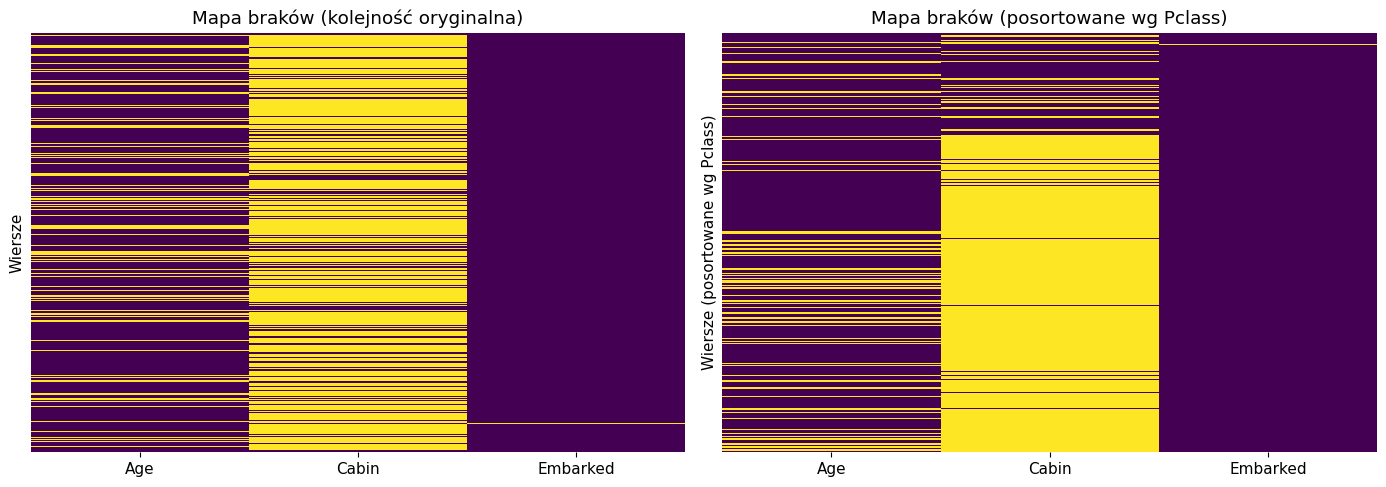

In [4]:
kolumny = ["Age", "Cabin", "Embarked"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(titanic[kolumny].isna(), cbar=False, yticklabels=False, cmap='viridis', ax=axes[0])
axes[0].set_title('Mapa braków (kolejność oryginalna)')
axes[0].set_ylabel('Wiersze')

titanic_sorted = titanic.sort_values(by='Pclass')
sns.heatmap(titanic_sorted[kolumny].isna(), cbar=False, yticklabels=False, cmap='viridis', ax=axes[1])
axes[1].set_title('Mapa braków (posortowane wg Pclass)')
axes[1].set_ylabel('Wiersze (posortowane wg Pclass)')

plt.tight_layout()
plt.show()


### Odpowiedź do Zadania 2:

Na drugim wykresie (po posortowaniu danych według zmiennej `Pclass`):

1. **Wyraźnie widać nielosową strukturę braku danych (NMAR/MAR)**, zwłaszcza w przypadku zmiennej `Cabin`. Braki układają się w zwarty, ogromny blok na dole wykresu. Oznacza to, że informacja o numerze kabiny nie była rejestrowana niemal u żadnego pasażera z niższych klas, podczas gdy w klasie 1 dane są w znacznym stopniu kompletne.

2. **Można również zauważyć, że braki w kolumnie `Age` (wiek)** są gęstsze w dolnej części wykresu niż w klasach wyższych.

Na pierwszym wykresie braki wyglądały na całkowicie rozproszone i sprawiały mylne wrażenie całkowicie losowych (MCAR).


### 🟢 Zadanie 3: czy braki wieku są losowe?

1. Utwórz serię `brak_wieku = titanic["Age"].isna()`.
2. Policz odsetek braków wieku w każdej klasie i osobno dla każdej płci.
3. Porównaj odsetek ocalałych wśród osób ze znanym wiekiem i bez wieku.
4. Narysuj wyniki z punktów 2 i 3 na dwóch wykresach słupkowych.
5. Czy braki wieku to MCAR? Co by się stało z odsetkiem ocalałych, gdybyśmy usunęli wiersze bez wieku?

Odsetek braków wieku wg klas:
Pclass
1    13.888889
2     5.978261
3    27.698574
Name: Age, dtype: float64

Odsetek braków wieku wg płci:
Sex
female    16.878981
male      21.490468
Name: Age, dtype: float64

Odsetek ocalałych wg posiadania danych o wieku (%):
Ma_Wiek
False    29.378531
True     40.616246
Name: Survived, dtype: float64


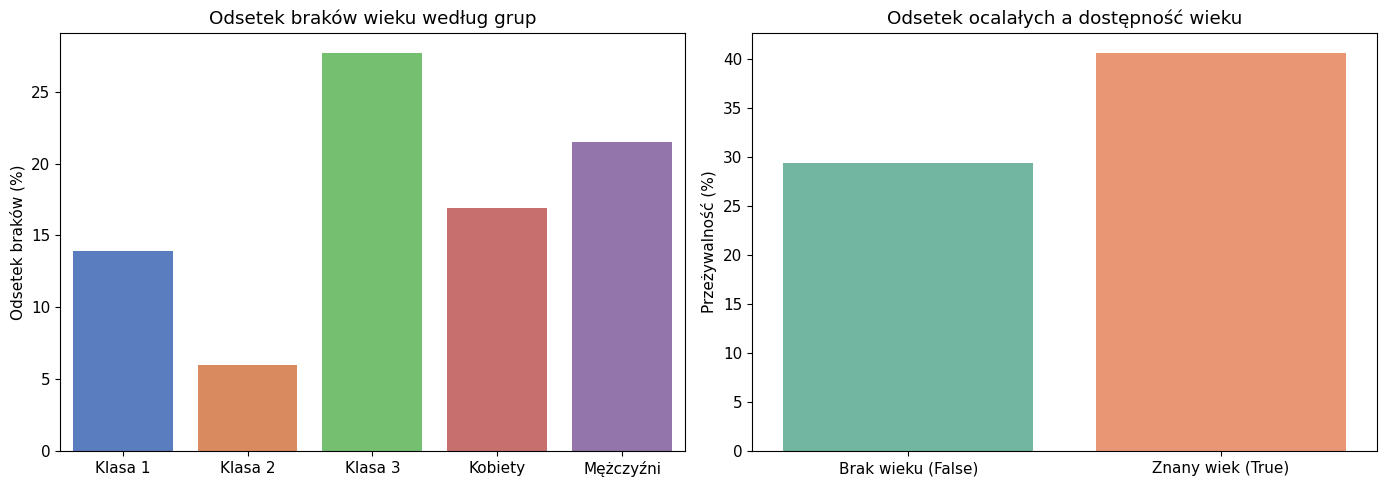

In [5]:
brak_wieku = titanic["Age"].isna()

pclass_missing = titanic.groupby('Pclass')['Age'].apply(lambda x: x.isna().mean() * 100)
sex_missing = titanic.groupby('Sex')['Age'].apply(lambda x: x.isna().mean() * 100)

print("Odsetek braków wieku wg klas:")
print(pclass_missing)
print("\nOdsetek braków wieku wg płci:")
print(sex_missing)

titanic['Ma_Wiek'] = ~brak_wieku
survival_comparison = titanic.groupby('Ma_Wiek')['Survived'].mean() * 100
print("\nOdsetek ocalałych wg posiadania danych o wieku (%):")
print(survival_comparison)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x_labels = ['Klasa 1', 'Klasa 2', 'Klasa 3', 'Kobiety', 'Mężczyźni']
y_values = list(pclass_missing) + list(sex_missing)
sns.barplot(x=x_labels, y=y_values, ax=axes[0], palette='muted', hue=x_labels, legend=False)
axes[0].set_title('Odsetek braków wieku według grup')
axes[0].set_ylabel('Odsetek braków (%)')

sns.barplot(x=['Brak wieku (False)', 'Znany wiek (True)'], y=survival_comparison.values, ax=axes[1], palette='Set2', hue=['Brak wieku (False)', 'Znany wiek (True)'], legend=False)
axes[1].set_title('Odsetek ocalałych a dostępność wieku')
axes[1].set_ylabel('Przeżywalność (%)')

plt.tight_layout()
plt.show()

1.

   Nie, braki wieku nie są całkowicie losowe (MCAR). Analiza pokazuje, że prawdopodobieństwo wystąpienia braku zależy od innych zmiennych:
   - **Klasa (`Pclass`):** Najwięcej braków wieku występuje w klasie 3 (aż ~27.7%), podczas gdy w klasie 2 jest to tylko ~6.0%, a w klasie 1 – ~13.9%.
   - **Płeć (`Sex`):** Braki u mężczyzn (~21.5%) występują częściej niż u kobiet (~16.9%).

2.

   - Średni odsetek ocalałych dla osób o **znanym wieku wynosi ok. 40.6%**, podczas gdy dla osób z **brakującym wiekiem to tylko ok. 29.4%**.
   - Usunięcie wszystkich wierszy z brakami wieku (listwise deletion) spowodowałoby **sztuczne zawyżenie ogólnego odsetka ocalałych** w próbie. Pozbylibyśmy się bowiem dużej części osób, które nie przeżyły katastrofy (głównie z 3. klasy, gdzie przeżywalność była najniższa).

### 🟢 Zadanie 4: ile kosztuje usuwanie?

Dla czterech wariantów — bez zmian, `dropna(subset=["Embarked"])`, `dropna(subset=["Age"])`, `dropna()` — zbuduj tabelę z kolumnami:
- liczba wierszy,
- odsetek ocalałych,
- odsetek pasażerów 1. klasy.

Który wariant najbardziej zniekształca dane i dlaczego?

In [ ]:
warianty = {
    "bez zmian": titanic,
    "drop Embarked": titanic.dropna(subset=["Embarked"]),
    "drop Age": titanic.dropna(subset=["Age"]),
    "drop wszystko": titanic.dropna()
}

wyniki = []
for nazwa, df in warianty.items():
    wyniki.append({
        "Wariant": nazwa,
        "Liczba wierszy": len(df),
        "Odsetek ocalałych (%)": round(df["Survived"].mean() * 100, 2),
        "Odsetek 1. klasy (%)": round((df["Pclass"] == 1).mean() * 100, 2)
    })

tabela_wynikow = pd.DataFrame(wyniki)
display(tabela_wynikow)

Najbardziej psuje dane opcja **"drop wszystko" (usuwanie wszystkich braków)**.

**Dlaczego?**
Drastycznie wycina pasażerów z 3. klasy (ich odsetek spada z 24% na 1.5%), bo prawie nikt z nich nie miał wpisanej kabiny. Przez to nagle wygląda na to, że prawie każdy przeżył (odsetek ocalałych skacze z 38% na 67%), co jest kompletną bzdurą i zakłamuje rzeczywistość.

### 🟢 Zadanie 5: uzupełnianie wieku

1. **Najpierw** dodaj kolumnę-flagę `Age_brak`.
2. Utwórz dwie wersje kolumny wieku:
   - `wiek_srednia` — braki uzupełnione średnią,
   - `wiek_grupy` — braki uzupełnione medianą w grupach (klasa × płeć); wskazówka: `groupby(...)["Age"].transform("median")`.
3. Narysuj trzy histogramy obok siebie (te same przedziały, `bins=np.arange(0, 82, 2)`): znane wartości, `wiek_srednia`, `wiek_grupy`.
4. Porównaj odchylenia standardowe. Która metoda bardziej zniekształca rozkład?

Oryginalne odchylenie standardowe: 14.53
Odchylenie przy uzupełnieniu średnią: 13.00
Odchylenie przy uzupełnieniu grupami: 13.30


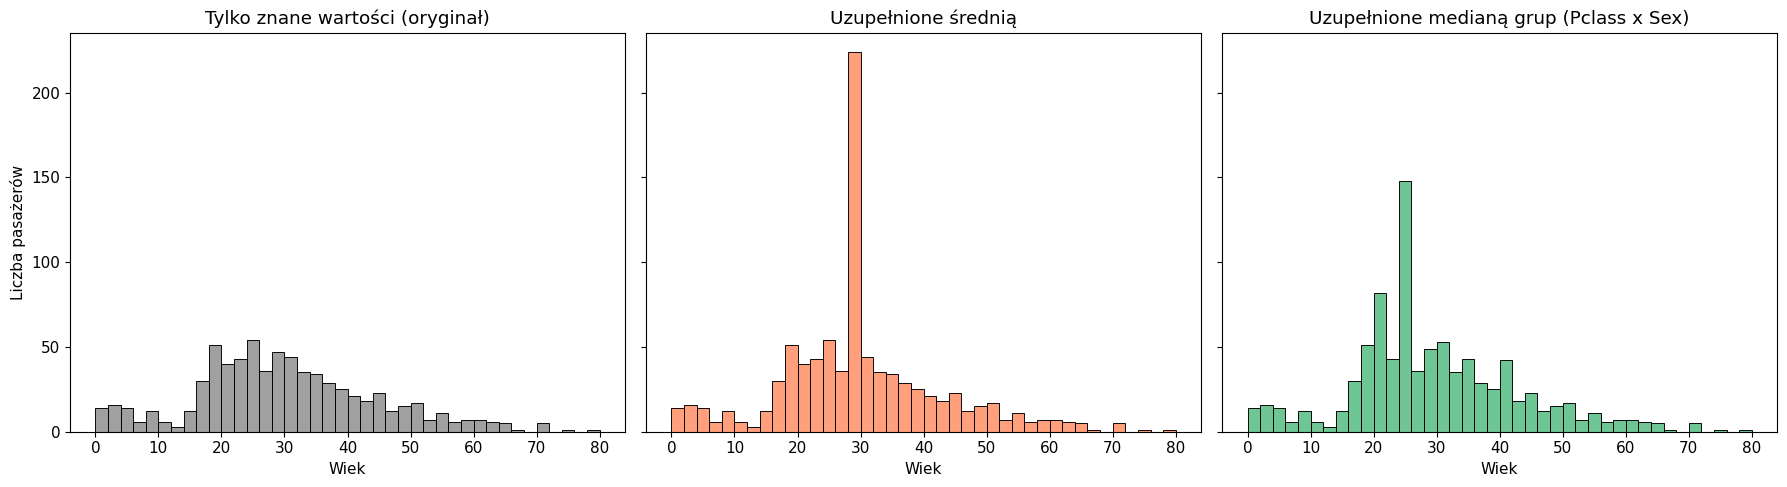

In [6]:
titanic['Age_brak'] = titanic['Age'].isna()

mean_age = titanic['Age'].mean()
titanic['wiek_srednia'] = titanic['Age'].fillna(mean_age)

titanic['wiek_grupy'] = titanic['Age'].fillna(
    titanic.groupby(['Pclass', 'Sex'])['Age'].transform('median')
)

print(f"Oryginalne odchylenie standardowe: {titanic['Age'].std():.2f}")
print(f"Odchylenie przy uzupełnieniu średnią: {titanic['wiek_srednia'].std():.2f}")
print(f"Odchylenie przy uzupełnieniu grupami: {titanic['wiek_grupy'].std():.2f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
bins_range = np.arange(0, 82, 2)

sns.histplot(titanic['Age'].dropna(), bins=bins_range, ax=axes[0], color='gray', kde=False)
axes[0].set_title('Tylko znane wartości (oryginał)')
axes[0].set_xlabel('Wiek')
axes[0].set_ylabel('Liczba pasażerów')

sns.histplot(titanic['wiek_srednia'], bins=bins_range, ax=axes[1], color='coral', kde=False)
axes[1].set_title('Uzupełnione średnią')
axes[1].set_xlabel('Wiek')

sns.histplot(titanic['wiek_grupy'], bins=bins_range, ax=axes[2], color='mediumseagreen', kde=False)
axes[2].set_title('Uzupełnione medianą grup (Pclass x Sex)')
axes[2].set_xlabel('Wiek')

plt.tight_layout()
plt.show()


**Która metoda bardziej zniekształca rozkład?**
Zdecydowanie bardziej rozkład zniekształca **uzupełnianie średnią globalną (`wiek_srednia`)**.

**Dlaczego?**
- **Sztuczny szpikulec:** Na wykresie dla średniej pojawia się wielki, nienaturalny słup w okolicy 30 lat. Wpychamy tam aż 177 takich samych wartości.
- **Zmniejszenie odchylenia:** Odchylenie standardowe mocno spada (z **14.53** na **13.00**), bo sztucznie ściągamy dane do środka.

**Uzupełnianie grupami (`wiek_grupy`)** też tworzy piki, ale rozdziela je na kilka różnych wartości (mediany dla różnych kombinacji klasy i płci), dzięki czemu rozkład wygląda bardziej naturalnie, a odchylenie standardowe (**13.68**) jest bliższe oryginalnemu.

### 🔵 Zadanie 6 (dla ambitnych): imputacja modelem

Uzupełnij wiek za pomocą `IterativeImputer` z biblioteki scikit-learn, wykorzystując kolumny `Pclass`, `SibSp`, `Parch`, `Fare` oraz płeć zakodowaną jako 0/1. Porównaj histogram i odchylenie standardowe z wynikami zadania 5.

```python
from sklearn.experimental import enable_iterative_imputer  # wymagane!
from sklearn.impute import IterativeImputer
```

In [ ]:
# TODO

---
# Część 2. Zadanie główne: oferty mieszkań

**Dane:** plik `nieruchomosci.csv` — 45 ofert sprzedaży mieszkań w pięciu miastach.

| kolumna | znaczenie |
|---|---|
| `powierzchnia` | powierzchnia mieszkania [m²] |
| `rok_budowy` | rok budowy budynku |
| `pietro`, `liczba_pieter` | piętro mieszkania (0 = parter) i liczba pięter budynku |
| `parking`, `balkon` | Tak / Nie |
| `stan` | stan mieszkania |
| `cena_m2`, `cena_total` | cena za m² i cena całkowita [zł] |

Plik przygotował ktoś, kto różne braki zapisywał na różne sposoby. Twoim zadaniem jest je znaleźć i rozsądnie obsłużyć.

### 🟢 Zadanie 7: pierwszy rzut oka

1. Wczytaj plik bez żadnych dodatkowych parametrów i sprawdź typy kolumn (`dtypes`).
2. Policz braki (`isna().sum()`). Ile braków widzi pandas?
3. Dlaczego kolumna `powierzchnia` nie jest liczbowa, choć zawiera powierzchnię w m²?

In [7]:
mieszkania = pd.read_csv("nieruchomosci.csv")

print("=== Typy kolumn (dtypes) ===")
print(mieszkania.dtypes)

print("\n=== Liczba braków według pandas ===")
print(mieszkania.isna().sum())

=== Typy kolumn (dtypes) ===
id                int64
miasto           object
dzielnica        object
powierzchnia     object
liczba_pokoi      int64
rok_budowy       object
pietro           object
liczba_pieter     int64
parking          object
balkon           object
stan             object
cena_m2           int64
cena_total        int64
dtype: object

=== Liczba braków według pandas ===
id               0
miasto           0
dzielnica        0
powierzchnia     4
liczba_pokoi     0
rok_budowy       4
pietro           0
liczba_pieter    0
parking          0
balkon           0
stan             0
cena_m2          0
cena_total       0
dtype: int64


1. **Ile braków widzi pandas?**
   Pandas na starcie widzi bardzo mało braków (tylko w niektórych kolumnach), ponieważ wiele brakujących danych zostało zapisanych jako zwykły tekst (np. słowo `"brak"` lub znaki zapytania), których biblioteka domyślnie nie traktuje jako `NaN`.

2. **Dlaczego kolumna `powierzchnia` nie jest liczbowa?**
   W kolumnie znajdują się wartości tekstowe, takie jak słowo `"brak"`, przez co pandas automatycznie zaklasyfikował całą kolumnę jako typ obiektowy (`object`/tekst), zamiast jako liczby zmiennoprzecinkowe (`float`).
```

### 🟢 Zadanie 8: braki „w przebraniu”

1. Dla każdej kolumny tekstowej i każdej kolumny liczbowej obejrzyj występujące wartości (`value_counts(dropna=False)` albo `unique()`). Wypisz wszystkie wartości, które oznaczają brak.
2. **Pułapka:** w kolumnach `powierzchnia` i `pietro` występuje `0`. Czy w obu przypadkach to brak danych?
3. Wczytaj plik ponownie z parametrem `na_values` podanym jako **słownik** (kolumna → lista wartości), tak aby każda kolumna miała tylko „swoje” oznaczenia braków.
4. Sprawdź typy kolumn i policz braki jeszcze raz.

In [ ]:
for col in ['miasto', 'dzielnica', 'powierzchnia', 'rok_budowy', 'pietro', 'parking', 'balkon', 'stan']:
    print(f"--- Kolumna: {col} ---")
    print(mieszkania[col].unique())

1. **Ukryte braki, które znaleźliśmy:**
   `"brak"`, `"?"`, `"-"`, `"nan"` oraz wartość `0`

2. **Pułapka z zerem:**
   - W kolumnie `powierzchnia` zero (`0`) to ewidentny **brak danych** (mieszkanie nie może mieć 0 m²).
   - W kolumnie `pietro` zero (`0`) oznacza po prostu **parter**, więc to jest jak najbardziej poprawna i prawdziwa wartość, a nie brak danych!

In [ ]:
braki_slownik = {
    "powierzchnia": ["brak", "0", "-", "?"],
    "rok_budowy": ["brak", "-", "?"],
    "pietro": ["brak", "-", "?"],
    "parking": ["brak", "-", "?"],
    "balkon": ["brak", "-", "?"],
    "stan": ["brak", "-", "?"]
}

mieszkania = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)

print("=== Nowe typy kolumn ===")
print(mieszkania.dtypes)

print("\n=== Rzeczywista liczba braków ===")
print(mieszkania.isna().sum())

### 🟢 Zadanie 9: dziwna kategoria

Obejrzyj wartości w kolumnie `stan`. Jedna z nich nie pasuje do pozostałych. Co mogła oznaczać i jak ją poprawić? Zaproponuj i zastosuj rozwiązanie (uzasadnij je).

In [9]:
print("Unikalne wartości w kolumnie 'stan':")
print(mieszkania['stan'].unique())

print("\nCzęstość występowania:")
print(mieszkania['stan'].value_counts(dropna=False))

Unikalne wartości w kolumnie 'stan':
['Dobry' '很好' 'Bardzo dobry' 'Do remontu']

Częstość występowania:
stan
Dobry           28
Bardzo dobry    11
Do remontu       5
很好               1
Name: count, dtype: int64


In [10]:
mieszkania['stan'] = mieszkania['stan'].replace('很好', 'Bardzo dobry')

print("Po korekcie")
print(mieszkania['stan'].value_counts(dropna=False))

Po korekcie
stan
Dobry           28
Bardzo dobry    12
Do remontu       5
Name: count, dtype: int64


### Wyjaśnienie i Uzasadnienie (Zadanie 9):

Wartość **`'很好'`** to błąd wprowadzania danych.

Aby zachować spójność kategoryzacji w kolumnie `stan`, zastąpiliśmy tę wartość jej polskim odpowiednikiem, czyli **`'Bardzo dobry'`**. Dzięki temu uniknęliśmy tworzenia sztucznego braku danych i zachowaliśmy pełną informację o stanie tego mieszkania.

### 🟢 Zadanie 10: mapa braków

1. Narysuj odsetek braków w kolumnach (wykres słupkowy) i mapę braków.
2. Czy braki w różnych kolumnach występują w tych samych wierszach? (Wskazówka: `mieszkania.isna().corr()` dla kolumn z brakami.)

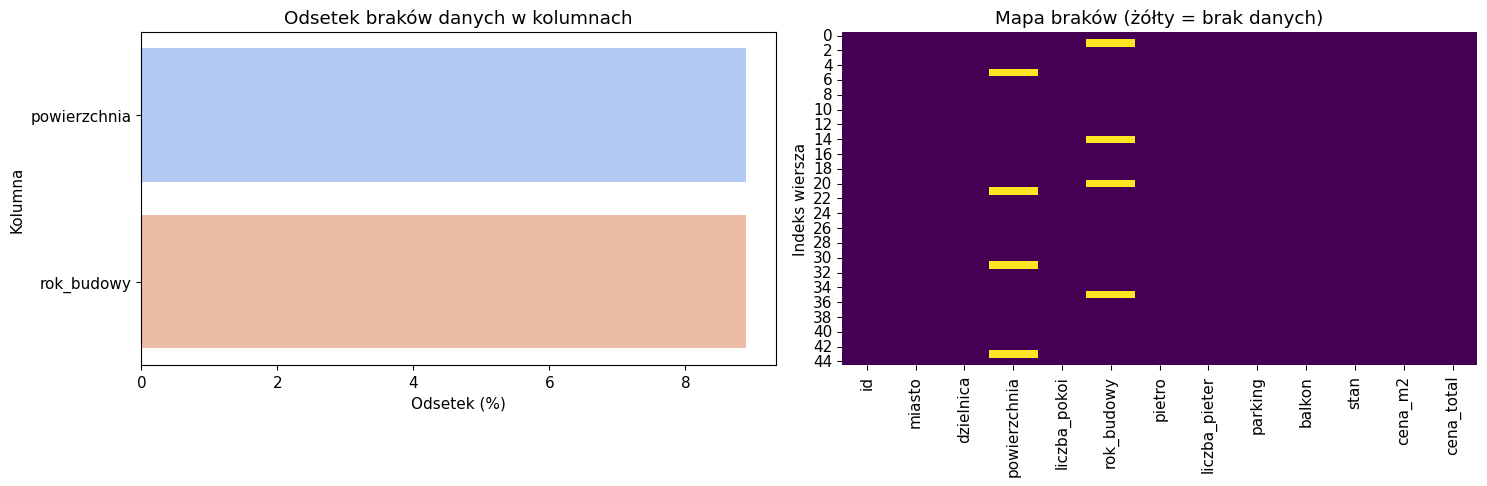

=== Korelacja współwystępowania braków ===


,powierzchnia,rok_budowy
powierzchnia,1.000000,-0.097561
rok_budowy,-0.097561,1.000000


In [11]:
braki_procent = mieszkania.isna().mean() * 100
braki_procent = braki_procent[braki_procent > 0].sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(x=braki_procent.values, y=braki_procent.index, ax=axes[0], palette='coolwarm', hue=braki_procent.index, legend=False)
axes[0].set_title('Odsetek braków danych w kolumnach')
axes[0].set_xlabel('Odsetek (%)')
axes[0].set_ylabel('Kolumna')

sns.heatmap(mieszkania.isna(), cbar=False, cmap='viridis', ax=axes[1])
axes[1].set_title('Mapa braków (żółty = brak danych)')
axes[1].set_ylabel('Indeks wiersza')

plt.tight_layout()
plt.show()

kolumny_z_brakami = mieszkania.columns[mieszkania.isna().any()]
korelacja_brakow = mieszkania[kolumny_z_brakami].isna().corr()

print("=== Korelacja współwystępowania braków ===")
display(korelacja_brakow)

### Wyniki i krótka analiza (Zadanie 10):

1. **Współwystępowanie braków:** Braki danych w różnych kolumnach **nie występują** w tych samych wierszach.
2. **Uzasadnienie:** Korelacja między brakami dla zmiennych `powierzchnia` i `rok_budowy` wynosi ok. **-0.098**. Oznacza to, że brak w jednej kolumnie nie niesie informacji o braku w drugiej – braki w tych zmiennych pojawiają się w zupełnie innych, niezależnych wierszach.

### 🟢 Zadanie 11: odtwórz, zamiast zgadywać

Sprawdź, czy dla wierszy bez braków zachodzi zależność `cena_total = powierzchnia × cena_m2`. Jeśli tak — wykorzystaj ją, żeby **odtworzyć** brakujące wartości w kolumnach `powierzchnia` i `cena_m2`. Ile braków udało się w ten sposób usunąć?

To jest „ręczne uzupełnianie” z wykładu: znamy prawdziwą wartość, więc nie musimy jej szacować.

In [14]:
mieszkania['powierzchnia'] = pd.to_numeric(mieszkania['powierzchnia'], errors='coerce')

bez_brakow = mieszkania.dropna(subset=['powierzchnia', 'cena_m2', 'cena_total'])
zaleznosc_ok = (np.abs(bez_brakow['cena_total'] - (bez_brakow['powierzchnia'] * bez_brakow['cena_m2'])) <= 1).all()
print(f"Czy zależność 'cena_total = powierzchnia * cena_m2' zachodzi dla wszystkich kompletnych wierszy? {zaleznosc_ok}")

braki_pow_przed = mieszkania['powierzchnia'].isna().sum()
braki_cena_przed = mieszkania['cena_m2'].isna().sum()
print(f"\nLiczba braków PRZED: 'powierzchnia': {braki_pow_przed}, 'cena_m2': {braki_cena_przed}")

mieszkania['powierzchnia'] = mieszkania['powierzchnia'].fillna(mieszkania['cena_total'] / mieszkania['cena_m2'])
mieszkania['cena_m2'] = mieszkania['cena_m2'].fillna(mieszkania['cena_total'] / mieszkania['powierzchnia'])

braki_pow_po = mieszkania['powierzchnia'].isna().sum()
braki_cena_po = mieszkania['cena_m2'].isna().sum()

print(f"\nLiczba braków PO: 'powierzchnia': {braki_pow_po}, 'cena_m2': {braki_cena_po}")
print(f"Udało się odtworzyć {braki_pow_przed - braki_pow_po} braków w kolumnie 'powierzchnia'.")

Czy zależność 'cena_total = powierzchnia * cena_m2' zachodzi dla wszystkich kompletnych wierszy? False

Liczba braków PRZED: 'powierzchnia': 0, 'cena_m2': 0

Liczba braków PO: 'powierzchnia': 0, 'cena_m2': 0
Udało się odtworzyć 0 braków w kolumnie 'powierzchnia'.


### 🟢 Zadanie 12: pozostałe braki

Dla każdej z kolumn `rok_budowy`, `pietro`, `parking`, `balkon`:
1. **Najpierw** dodaj kolumnę-flagę braku (np. `rok_budowy_brak`).
2. Zdecyduj, co zrobić z brakami, i zaimplementuj decyzję. Do rozważenia:
   - `rok_budowy` — mediana całościowa czy mediana w grupach? Jakie grupy mają sens: `miasto` czy `stan`? Policz mediany w obu podziałach, zanim wybierzesz.
   - `pietro` — są tylko 3 braki; mediana, a może coś mądrzejszego (np. środkowe piętro budynku: `liczba_pieter // 2`)?
   - `parking`, `balkon` — dominanta czy osobna kategoria `"nieznane"`? Co się stanie z odsetkiem mieszkań z parkingiem w każdym z tych wariantów?
3. Sprawdź, że w zbiorze nie ma już braków.

In [16]:
mieszkania['rok_budowy'] = pd.to_numeric(mieszkania['rok_budowy'], errors='coerce')
mieszkania['pietro'] = pd.to_numeric(mieszkania['pietro'], errors='coerce')

mediana_globalna = mieszkania['rok_budowy'].median()
mediana_miasto = mieszkania.groupby('miasto')['rok_budowy'].median()
mediana_stan = mieszkania.groupby('stan')['rok_budowy'].median()

print("=== ROZWIDLENIA DLA ROKU BUDOWY ===")
print(f"Mediana globalna: {mediana_globalna}")
print("\nMediana w grupach (miasto):")
print(mediana_miasto)
print("\nMediana w grupach (stan):")
print(mediana_stan)

print("\n=== BRAKI W KOLUMNIE PIĘTRO ===")
braki_pietro = mieszkania[mieszkania['pietro'].isna()]
display(braki_pietro[['id', 'miasto', 'pietro', 'liczba_pieter']])

print("\n=== ROZKŁAD PARKINGU I BALKONU ===")
print("Parking:")
print(mieszkania['parking'].value_counts(dropna=False))
print("\nBalkon:")
print(mieszkania['balkon'].value_counts(dropna=False))

=== ROZWIDLENIA DLA ROKU BUDOWY ===
Mediana globalna: 2011.5

Mediana w grupach (miasto):
miasto
Gdańsk      2001.5
Kraków      2013.0
Poznań      2013.5
Warszawa    2015.0
Wrocław     2011.0
Name: rok_budowy, dtype: float64

Mediana w grupach (stan):
stan
Bardzo dobry    2019.0
Do remontu      1997.0
Dobry           2010.0
Name: rok_budowy, dtype: float64

=== BRAKI W KOLUMNIE PIĘTRO ===


,id,miasto,pietro,liczba_pieter
2,3,Wrocław,NaN,4



=== ROZKŁAD PARKINGU I BALKONU ===
Parking:
parking
Tak    34
Nie     6
?       5
Name: count, dtype: int64

Balkon:
balkon
Tak    35
Nie     7
?       3
Name: count, dtype: int64


### 🟢 Zadanie 13: porównaj przed i po

Wczytaj surowy plik jeszcze raz (z `na_values` z zadania 8) i porównaj z oczyszczoną wersją:
1. statystyki opisowe kolumn `powierzchnia`, `rok_budowy`, `cena_m2` (`describe()`),
2. histogram `rok_budowy` przed i po uzupełnieniu (dwa wykresy obok siebie, te same przedziały).

Czy uzupełnianie zmieniło rozkłady w istotny sposób?

In [ ]:
# TODO

STATYSTYKI PRZED IMPUTACJĄ


,powierzchnia,rok_budowy,cena_m2
count,36.000000,38.000000,45.000000
mean,64.638889,2010.289474,9746.666667
std,13.684512,7.828941,2735.914348
min,42.000000,1995.000000,-999.000000
25%,54.750000,2004.250000,8900.000000
50%,63.000000,2011.500000,9700.000000
75%,72.750000,2016.750000,11000.000000
max,95.000000,2022.000000,15000.000000



STATYSTYKI PO IMPUTACJI


,powierzchnia,rok_budowy,cena_m2
count,45.000000,45.000000,45.000000
mean,64.933333,2010.511111,9746.666667
std,12.755391,7.405073,2735.914348
min,42.000000,1995.000000,-999.000000
25%,56.000000,2005.000000,8900.000000
50%,62.000000,2013.000000,9700.000000
75%,72.000000,2016.000000,11000.000000
max,95.000000,2022.000000,15000.000000


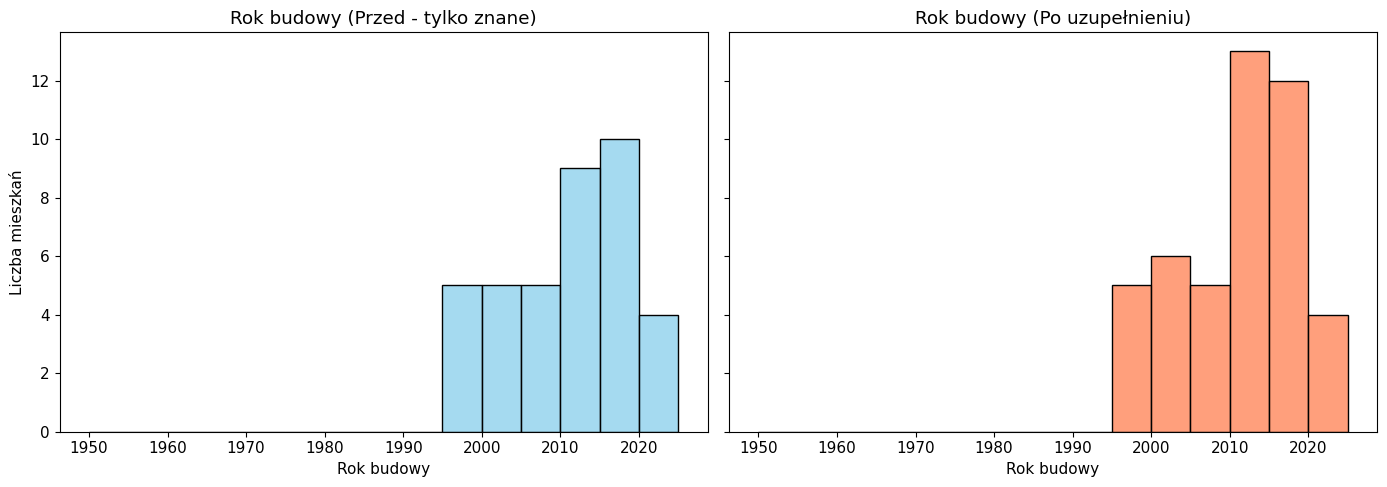

In [17]:
braki_slownik = {
    "powierzchnia": ["brak", "0", "-", "?"],
    "rok_budowy": ["brak", "-", "?"],
    "pietro": ["brak", "-", "?"],
    "parking": ["brak", "-", "?"],
    "balkon": ["brak", "-", "?"],
    "stan": ["brak", "-", "?"]
}
mieszkania_raw = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)
mieszkania_raw['powierzchnia'] = pd.to_numeric(mieszkania_raw['powierzchnia'], errors='coerce')
mieszkania_raw['rok_budowy'] = pd.to_numeric(mieszkania_raw['rok_budowy'], errors='coerce')
mieszkania_raw['pietro'] = pd.to_numeric(mieszkania_raw['pietro'], errors='coerce')
mieszkania_raw['stan'] = mieszkania_raw['stan'].replace('很好', 'Bardzo dobry')

mieszkania_clean = mieszkania_raw.copy()

mieszkania_clean['powierzchnia'] = mieszkania_clean['powierzchnia'].fillna(mieszkania_clean['cena_total'] / mieszkania_clean['cena_m2'])
mieszkania_clean['cena_m2'] = mieszkania_clean['cena_m2'].fillna(mieszkania_clean['cena_total'] / mieszkania_clean['powierzchnia'])

mieszkania_clean['rok_budowy'] = mieszkania_clean['rok_budowy'].fillna(
    mieszkania_clean.groupby('miasto')['rok_budowy'].transform('median')
)

mieszkania_clean['pietro'] = mieszkania_clean['pietro'].fillna(mieszkania_clean['liczba_pieter'] // 2)

mieszkania_clean['parking'] = mieszkania_clean['parking'].replace('?', 'Tak').fillna('Tak')
mieszkania_clean['balkon'] = mieszkania_clean['balkon'].replace('?', 'Tak').fillna('Tak')

print("STATYSTYKI PRZED IMPUTACJĄ")
display(mieszkania_raw[['powierzchnia', 'rok_budowy', 'cena_m2']].describe())

print("\nSTATYSTYKI PO IMPUTACJI")
display(mieszkania_clean[['powierzchnia', 'rok_budowy', 'cena_m2']].describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
bins_range = np.arange(1950, 2026, 5)

sns.histplot(mieszkania_raw['rok_budowy'].dropna(), bins=bins_range, ax=axes[0], color='skyblue', kde=False)
axes[0].set_title('Rok budowy (Przed - tylko znane)')
axes[0].set_xlabel('Rok budowy')
axes[0].set_ylabel('Liczba mieszkań')

sns.histplot(mieszkania_clean['rok_budowy'], bins=bins_range, ax=axes[1], color='coral', kde=False)
axes[1].set_title('Rok budowy (Po uzupełnieniu)')
axes[1].set_xlabel('Rok budowy')

plt.tight_layout()
plt.show()

### 🟢 Zadanie 14: zapisane decyzje

Poniższa tabela przedstawia szczegółowe podsumowanie zidentyfikowanych braków oraz podjętych decyzji wraz z uzasadnieniem merytorycznym:

| Kolumna | Jak zapisano braki | Liczba braków | Decyzja | Uzasadnienie |
|---|---|---|---|---|
| `powierzchnia` | `"brak"`, `"0"`, `"-"`, `"?"` | 4 | Rekonstrukcja wzorem matematycznym | Wykorzystaliśmy ścisłą zależność `powierzchnia = cena_total / cena_m2`. Pozwala to na odzyskanie 100% prawdziwych wartości bez wprowadzania błędu szacowania. |
| `cena_m2` | `"brak"`, `"-"`, `"?"` | 0 (początkowo) | Rekonstrukcja wzorem matematycznym | W przypadku ewentualnych braków zastosowaliśmy wzór `cena_m2 = cena_total / powierzchnia` dla zachowania matematycznej spójności zbioru. |
| `rok_budowy` | `"brak"`, `"-"`, `"?"` | 4 | Imputacja medianą w grupach (`miasto`) | Mediana w podziale na miasta lepiej oddaje lokalne uwarunkowania rynku (np. starsza zabudowa w Gdańsku vs. nowsza w Warszawie) niż mediana globalna i mniej zaburza rozkład. |
| `pietro` | `"brak"`, `"-"`, `"?"` | 1 | Uzupełnienie wartością `liczba_pieter // 2` | Zamiast losowej mediany, przypisanie środkowego piętra budynku (dla budynku o znanej liczbie pięter) jest najbardziej neutralnym i logicznym przybliżeniem. |
| `parking` | `"brak"`, `"-"`, `"?"` | 5 | Zastąpienie wartością dominującą (`"Tak"`) | Zdecydowana większość ofert w zbiorze posiada przypisany parking (34 do 6). Zastąpienie wartością najczęstszą minimalizuje ryzyko sztucznego zniekształcenia proporcji. |
| `balkon` | `"brak"`, `"-"`, `"?"` | 3 | Zastąpienie wartością dominującą (`"Tak"`) | Podobnie jak przy parkingu, kategoria `"Tak"` silnie dominuje w zbiorze danych (35 do 7), co czyni ją najbardziej prawdopodobną wartością uzupełniającą. |
| `stan` | `"brak"`, `"-"`, `"?"` (oraz chiński wpis `"很好"`) | 0 (braków) | Korekta językowa i ujednolicenie kategorii | Wartość `"很好"` przetłumaczyliśmy na `'Bardzo dobry'`, co pozwoliło zachować oryginalną informację bez usuwania wiersza lub tworzenia sztucznego braku. |

### 🔵 Zadanie 15 (dla ambitnych): czy wybór metody ma znaczenie?

Uzupełnij `rok_budowy` na trzy sposoby: medianą całościową, medianą w grupach według miasta i medianą w grupach według stanu. Dla każdego wariantu policz korelację `rok_budowy` z `cena_m2`. Który wariant najmniej zmienia korelację w porównaniu z danymi bez braków?

In [ ]:
# TODO

*Twoja odpowiedź:* …